In [ ]:
# wget -nc ftp://ftp.sra.ebi.ac.uk/vol1/analysis/ERZ266/ERZ266990/HPSI0114i-kolf_2.GRCh37.75.cdna.kallisto.transcripts.abundance.rnaseq.20160125.tsv


# Check if SYM101 targets are expressed in public KOLF2 RNA-seq data

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as pl

In [2]:
# Load public data from Hipsci.org
gex = pd.read_csv('/scratch/peidli/SYMPHONY/SYM101/KOLF2/HPSI0114i-kolf_2.GRCh37.75.cdna.kallisto.transcripts.abundance.rnaseq.20160125.tsv', sep='\t', index_col=0)
gex.columns = 'kolf_2_' + gex.columns.astype(str)

In [3]:
gex.tail()

,kolf_2_length,kolf_2_eff_length,kolf_2_est_counts,kolf_2_tpm
target_id,,,,
ENST00000450690,55,22.0645,0.0,0.0
ENST00000605523,50,19.8519,0.0,0.0
ENST00000605654,60,22.4737,0.0,0.0
ENST00000603923,55,22.0645,0.0,0.0
ENST00000600861,483,316.8390,0.0,0.0


In [27]:
# Load SYM101 target transcripts
sym101 = pd.read_csv("../resources/all_gRNA_data.csv", index_col='unique_guide_name')
sym101 = sym101[sym101.Gene != 'NT_Control']

In [28]:
sym101.tail()

,Transcript_ID,ensembl_gene_id,Gene,transcript_biotype,GuideName,GuideSeq,MatchPos,Guide_Score,Region,transcript_length,gRNA_occurence,transcript_per_gene
unique_guide_name,,,,,,,,,,,,
AFAP1-AS1_ENST00000608442_3741,ENST00000608442,ENSG00000272620,AFAP1-AS1,lncRNA,crRNA3583:3719-3741,AAATAAGCATTTATGTGTTGCCC,3741.0,0.969503,Gene_Body,6808.0,1,1
AFAP1-AS1_ENST00000608442_4117,ENST00000608442,ENSG00000272620,AFAP1-AS1,lncRNA,crRNA3959:4095-4117,TTATTCTTAATCATTATGCCACC,4117.0,0.890252,Gene_Body,6808.0,1,1
AFAP1-AS1_ENST00000608442_5002,ENST00000608442,ENSG00000272620,AFAP1-AS1,lncRNA,crRNA4747:4980-5002,ACAAGCAAAATCGGAGTCCCACG,5002.0,0.939375,Gene_Body,6808.0,1,1
AFAP1-AS1_ENST00000608442_6024,ENST00000608442,ENSG00000272620,AFAP1-AS1,lncRNA,crRNA5749:6002-6024,CACCAAGAGAGTAAGCAGCTCCC,6024.0,0.978346,Gene_Body,6808.0,1,1
AFAP1-AS1_ENST00000608442_6391,ENST00000608442,ENSG00000272620,AFAP1-AS1,lncRNA,crRNA6116:6369-6391,AGCATTTTAAAATAGGAGGCAGT,6391.0,0.963412,Gene_Body,6808.0,1,1


In [29]:
df = pd.merge(gex, sym101, left_index=True, right_on='Transcript_ID', how='right')

In [30]:
df.head()

,kolf_2_length,kolf_2_eff_length,kolf_2_est_counts,kolf_2_tpm,Transcript_ID,ensembl_gene_id,Gene,transcript_biotype,GuideName,GuideSeq,MatchPos,Guide_Score,Region,transcript_length,gRNA_occurence,transcript_per_gene
unique_guide_name,,,,,,,,,,,,,,,,
CYP26B1_ENST00000001146_2702,4732.0,5401.860,3.06977,0.022539,ENST00000001146,ENSG00000003137,CYP26B1,protein_coding,crRNA2661:2680-2702,TTAAACCCAAATAATGCCCGGAG,2702.0,1.306530,UTR3,4556.0,1,2
CYP26B1_ENST00000001146_4708,4732.0,5401.860,3.06977,0.022539,ENST00000001146,ENSG00000003137,CYP26B1,protein_coding,crRNA4464:4686-4708,AAGCCTATAGAAGAGCCACATTG,4708.0,1.411459,UTR3,4556.0,1,2
NDUFAB1_ENST00000007516_654,717.0,503.032,3195.36000,251.943000,ENST00000007516,ENSG00000004779,NDUFAB1,protein_coding,crRNA632:632-654,AAGTCCATCAGAATCACTCTGTC,654.0,1.012291,UTR3,665.0,1,1
NDUFAB1_ENST00000007516_667,717.0,503.032,3195.36000,251.943000,ENST00000007516,ENSG00000004779,NDUFAB1,protein_coding,crRNA645:645-667,ACAATTTAAATACAAGTCCATCA,667.0,0.996597,UTR3,665.0,1,1
RPS20_ENST00000009589_568,626.0,395.684,22396.80000,2245.000000,ENST00000009589,ENSG00000008988,RPS20,protein_coding,crRNA508:546-568,CTTTATATTCCTAAAATCTGCCA,568.0,0.821865,UTR3,519.0,1,1


In [31]:
sgex = gex[gex.index.isin(sym101.Transcript_ID.unique())]

In [32]:
sgex

,kolf_2_length,kolf_2_eff_length,kolf_2_est_counts,kolf_2_tpm
target_id,,,,
ENST00000427390,4091,4041.18,10.3669,0.101746
ENST00000299259,2036,1502.74,1693.0700,44.685600
ENST00000283645,3849,3285.75,644.9380,7.785060
ENST00000400075,4814,3601.04,1430.8500,15.759500
ENST00000255152,2773,2773.50,263.1820,3.763620
...,...,...,...,...
ENST00000340385,1751,1518.51,12610.6000,329.379000
ENST00000367600,2519,2815.94,3612.2800,50.878700
ENST00000367549,4240,3699.93,18768.8000,201.197000


In [33]:
sym101.Transcript_ID.unique().shape

(844,)

In [ ]:
sym101_n = len(sym101.Transcript_ID.unique())  # transcripts in SYM101
gex_n = len(sgex)  # overlap GEX and SYM101
expressed_n = sum(sgex['kolf_2_tpm'] > 1)  # expressed in SYM101

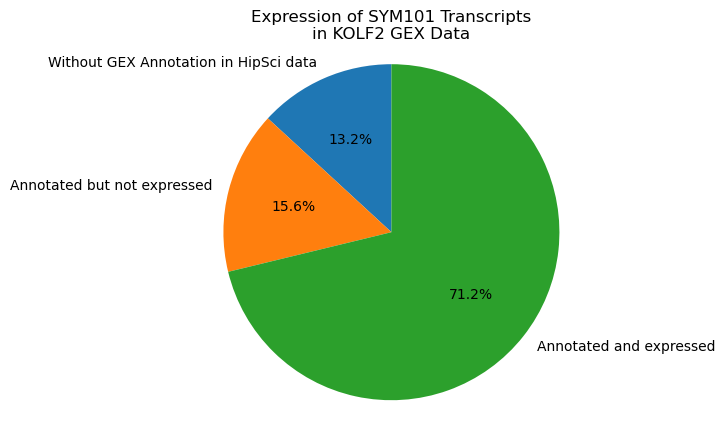

In [75]:
pl.pie([sym101_n - gex_n, gex_n - expressed_n, expressed_n], 
       labels=['Without GEX Annotation in HipSci data', 'Annotated but not expressed', 'Annotated and expressed'], 
       autopct='%1.1f%%', startangle=90)
pl.title('Expression of SYM101 Transcripts\nin KOLF2 GEX Data')
pl.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.
pl.savefig('../results/kolf2/KOLF2_GEX_SYM101_transcripts.png', dpi=300, bbox_inches='tight')
pl.show()


In [72]:
df['expressed'] = df['kolf_2_tpm'] > 1

In [74]:
df.to_csv('../results/kolf2/KOLF2_SYM101_expression_transcripts.tsv', sep='\t', index=True)

In [ ]:
# many transcripts in SYM101 are not in gex
# likely because of different transcriptome build
# Could map to genes?

In [76]:
import sys
# load functions from ../utils
sys.path.append('../utils')
from utils import annotate_essentiality


In [80]:
df['essentiality'] = annotate_essentiality(df.Gene)

In [87]:
cts = df.value_counts(['Gene', 'expressed', 'essentiality']).reset_index()
cts2 = cts.value_counts(['essentiality', 'expressed']).reset_index()

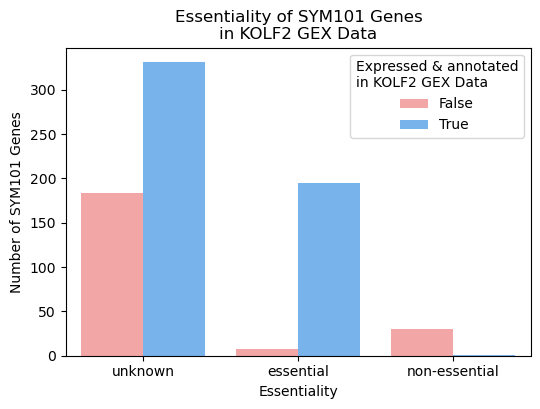

In [99]:
fig, ax = pl.subplots(figsize=(6, 4))
sns.barplot(data=cts2, x='essentiality', y='count', hue='expressed', palette=['#FF9999', '#66B3FF'], ax=ax)
ax.set_ylabel('Number of SYM101 Genes')
ax.set_xlabel('Essentiality')
ax.set_title('Essentiality of SYM101 Genes\nin KOLF2 GEX Data')
pl.legend(title='Expressed & annotated\nin KOLF2 GEX Data', loc='upper right')
pl.savefig('../results/kolf2/KOLF2_GEX_SYM101_essentiality.png', dpi=300, bbox_inches='tight')
pl.show()

In [100]:
cts2

,essentiality,expressed,count
0,unknown,True,331
1,essential,True,195
2,unknown,False,184
3,non-essential,False,30
4,essential,False,8
5,non-essential,True,1
